In [ ]:
import csv
import torch
import torch.nn as nn
import matplotlib.pyplot as plt


def read_csv(filename):
    celsius = []
    fahrenheit = []
    with open(filename, 'r', encoding='utf-8') as f:
        reader = csv.DictReader(f)
        for row in reader:
            celsius.append(float(row['Celsius']))
            if row['Fahrenheit']:  # testing.csv has no Fahrenheit values
                fahrenheit.append(float(row['Fahrenheit']))

    C = torch.tensor(celsius, dtype=torch.float32).reshape(-1, 1)
    F = torch.tensor(fahrenheit, dtype=torch.float32).reshape(-1, 1) if fahrenheit else None
    return C, F

C_train, F_train = read_csv('dataset/training.csv')
C_test, F_test = read_csv('dataset/testing.csv')

print("Train:", C_train.shape, F_train.shape)
print("Test :", C_test.shape, F_test)

Train: torch.Size([16000, 1]) torch.Size([16000, 1])
Test : torch.Size([8000, 1]) None


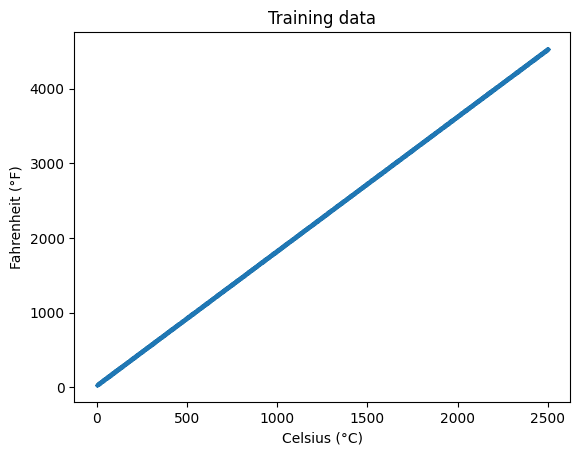

In [27]:
plt.scatter(C_train, F_train, s=2)
plt.xlabel("Celsius (°C)")
plt.ylabel("Fahrenheit (°F)")
plt.title("Training data")
plt.show()

In [28]:
# Prepare
import pandas as pd
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    C_train,
    F_train,
    test_size=0.2,       # Allocates 20% of the data for testing, 80% for training
    random_state=42,
)

print("X Train:",X_train.shape)
print("Y Train :",y_train.shape)
print("X Test",X_test.shape)

print("X_train [0]",X_train)

X Train: torch.Size([12800, 1])
Y Train : torch.Size([12800, 1])
X Test torch.Size([3200, 1])
X_train [0] tensor([[ 214.],
        [1951.],
        [1056.],
        ...,
        [ 736.],
        [ 952.],
        [1378.]])


In [29]:
# Normalize
# input: tensor → output: mean, std
# Goal : learn the scale (mean, std) from train data → reuse it everywhere


def fit_normalizer(x):
    mean = x.mean()
    std = x.std()
    return mean, std

X_mean , X_std = fit_normalizer(X_train)
y_mean, y_std = fit_normalizer(y_train)

print(X_mean, X_std)
print(y_mean, y_std)



tensor(1257.7872) tensor(725.7484)
tensor(2296.0171) tensor(1306.3470)


In [30]:
# Normalize function

def normalize(x, mean, std):
    return (x - mean) / std

def denormalize(z, mean , std):
    return z * std + mean

# Apply with the Normalize data

X_train_n = normalize(X_train, X_mean, X_std)
y_train_n = normalize(y_train,y_mean, y_std)
X_val_n = normalize(X_test, X_mean, X_std)
y_val_n = normalize(y_test, y_mean, y_std)
print("X_train_n:", X_train_n.mean().item(), X_train_n.std().item())  # ≈ 0, 1
print("y_train_n:", y_train_n.mean().item(), y_train_n.std().item())  # ≈ 0, 1
print("X_val_n  :", X_val_n.mean().item(),   X_val_n.std().item())    # close to 0, 1
print("round trip:", torch.allclose(denormalize(X_train_n, X_mean, X_std), X_train))  # True




X_train_n: -5.990266771505048e-08 1.0
y_train_n: -1.1548399925231934e-07 1.0
X_val_n  : -0.02102060243487358 1.0040380954742432
round trip: True


In [31]:
# Model
import torch.nn as nn

class TempModel(nn.Module):
    def __init__(self, in_features=1, out_features=1):
        super().__init__()
        # Given x (Celsius, input) and y (Fahrenheit, correct answer) → the model learns a, b in y = a·x + b
        self.layer = nn.Linear(in_features, out_features) # a and b live here

        # forward(x)  →  uses the current a and b  →  returns y_pred = a·x + b
    def forward(self, x):
        return self.layer(x)



torch.manual_seed(42)

model = TempModel(in_features=1, out_features=1)
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(),lr=0.01)

print("Model :",model)

print("a =", model.layer.weight.item(), " b =", model.layer.bias.item())
print("starting loss:", loss_fn(model(X_train_n), y_train_n).item())


# True answer , real units a = 1.8 and b = 32





Model : TempModel(
  (layer): Linear(in_features=1, out_features=1, bias=True)
)
a = 0.7645385265350342  b = 0.8300079107284546
starting loss: 0.7443509697914124


In [32]:
# Training

epochs = 500
train_losses = []

for epoch in range(1, epochs + 1):
    y_pred = model(X_train_n)   # 1. predict the y value
    loss = loss_fn(y_pred, y_train_n)  # 2. loss functions
    optimizer.zero_grad()  # 3. reset gradients (forget the last epoch's slope)
    loss.backward()  # 4. backward (Compute the New Slope)
    optimizer.step()  # 5. update a, b

    train_losses.append(loss.item())

    if epoch % 50 == 0 or epoch == 1:
        print(f"epoch {epoch:4d} | loss {loss.item():.6f} | "
              f"a {model.layer.weight.item():.4f} | b {model.layer.bias.item():.4f}")



epoch    1 | loss 0.744351 | a 0.7692 | b 0.8134
epoch   50 | loss 0.102787 | a 0.9142 | b 0.3023
epoch  100 | loss 0.013632 | a 0.9688 | b 0.1101
epoch  150 | loss 0.001808 | a 0.9886 | b 0.0401
epoch  200 | loss 0.000240 | a 0.9959 | b 0.0146
epoch  250 | loss 0.000032 | a 0.9985 | b 0.0053
epoch  300 | loss 0.000004 | a 0.9995 | b 0.0019
epoch  350 | loss 0.000001 | a 0.9998 | b 0.0007
epoch  400 | loss 0.000000 | a 0.9999 | b 0.0003
epoch  450 | loss 0.000000 | a 1.0000 | b 0.0001
epoch  500 | loss 0.000000 | a 1.0000 | b 0.0000


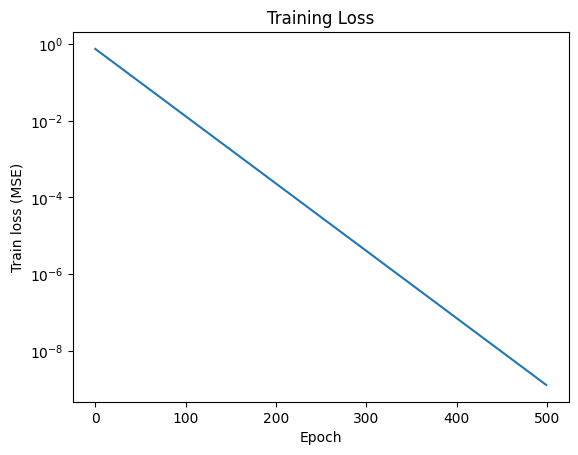

In [34]:
# Evaluate
# Goal : check the model on data is has never seen

# Loss curve
plt.plot(train_losses)
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Train loss (MSE)")
plt.title("Training Loss")
plt.show()

In [35]:
# Validation loss
model.eval()
with torch.no_grad():
    train_loss = loss_fn(model(X_train_n), y_train_n).item()
    val_loss = loss_fn(model(X_val_n), y_val_n).item()

print("Train loss",train_loss)
print("Val loss:",val_loss)

Train loss 1.2527304749099244e-09
Val loss: 1.267321469988758e-09


In [37]:
# Error in real F
with torch.no_grad():
    y_val_pred = denormalize(model(X_val_n), y_mean, y_std)

error = (y_val_pred - y_test).abs()
print("average error (°F):", error.mean().item())
print("max error (°F)    :", error.max().item())

for i in range(3):
    print(f"C = {X_test[i].item():6.0f} | true F = {y_test[i].item():8.2f} | predicted F = {y_val_pred[i].item():8.2f}")


average error (°F): 0.04473276063799858
max error (°F)    : 0.06645584106445312
C =   1434 | true F =  2613.20 | predicted F =  2613.24
C =   1627 | true F =  2960.60 | predicted F =  2960.64
C =   2108 | true F =  3826.40 | predicted F =  3826.43


In [ ]:
# Predict
# Goal : use the trained model on new data
# Step 1: Normalize the new data
C_test_n = normalize(C_test, X_mean, X_std)
print("C_test: ",C_test.shape)
print(C_test[0].item())
print(C_test_n[0].item())


C_test:  torch.Size([8000, 1])
259.0
-1.376217007637024


In [42]:
# Step 2: Predict - Run the model (test mode ,no gradients)
model.eval()
with torch.no_grad():
    y_test_pred_n = model(C_test_n)
    

In [43]:
# Step 3 : Denormalize back to F
F_test_pred = denormalize(y_test_pred_n, y_mean, y_std)
print("predictions:", F_test_pred.shape)

predictions: torch.Size([8000, 1])


In [45]:
# Step 4: compare with the true formula F = 1.8C + 32
F_true = 1.8 * C_test + 32
for i in range(5):
    print(f"C = {C_test[i].item():6.0f} | predicted F = {F_test_pred[i].item():8.2f} | true F = {F_true[i].item():8.2f}")

error = (F_test_pred - F_true).abs()
print("average error (°F):", error.mean().item())


C =    259 | predicted F =   498.26 | true F =   498.20
C =   2351 | predicted F =  4263.83 | true F =  4263.80
C =   2112 | predicted F =  3833.63 | true F =  3833.60
C =   2239 | predicted F =  4062.23 | true F =  4062.20
C =   1016 | predicted F =  1860.85 | true F =  1860.80
average error (°F): 0.04472244158387184


In [46]:
# Step 5: convert the learned a, b (normalized) → real units
a_n = model.layer.weight.item()
b_n = model.layer.bias.item()

a_real = a_n * y_std / X_std
b_real = y_mean + y_std * b_n - a_real * X_mean

print(f"normalized: a = {a_n:.4f}, b = {b_n:.4f}")
print(f"real      : a = {a_real.item():.4f}, b = {b_real.item():.4f}")
print("true      : a = 1.8, b = 32")


normalized: a = 1.0000, b = 0.0000
real      : a = 1.8000, b = 32.0664
true      : a = 1.8, b = 32
